# Titanic Survival Prediction - Data Cleaning Project

This assignment loads the built-in Titanic dataset from Seaborn, reviews its structure and summary statistics, handles missing values with mean/median/mode imputation, encodes `Sex` and `Embarked`, visualizes age distribution, and saves the cleaned data as a CSV.

The built-in dataset is downloaded by Seaborn on first use, so an internet connection may be needed. Alternatively, place Kaggle's `train.csv` beside this notebook and change the loading cell to `pd.read_csv("train.csv")`.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Load Seaborn's built-in Titanic dataset.
titanic = sns.load_dataset("titanic")
print(f"Dataset shape: {titanic.shape}")
display(titanic.head())

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Inspect the dataset and summarize basic statistics

In [2]:
print("Dataset information:")
titanic.info()

print("\nDescriptive statistics (numeric columns):")
display(titanic.describe())

print("\nDescriptive statistics (all columns):")
display(titanic.describe(include="all"))

print("\nMissing values by column:")
display(titanic.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB

Descriptive statistics (numeric columns):


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Descriptive statistics (all columns):


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,missing_count
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


## 2. Clean missing data

Use the mean for missing `age`, the median for missing `fare`, the mode for `embarked` and `embark_town`, and an `Unknown` category for the heavily-missing `deck` field. The example applies mean and median imputation to numeric columns and mode/category imputation to categorical columns.

In [3]:
cleaned = titanic.copy()

# Numeric imputation: mean for age and median for fare.
cleaned["age"] = cleaned["age"].fillna(cleaned["age"].mean())
cleaned["fare"] = cleaned["fare"].fillna(cleaned["fare"].median())

# Categorical imputation: most frequent value for these columns.
for column in ["embarked", "embark_town"]:
    most_frequent = cleaned[column].mode(dropna=True)
    if most_frequent.empty:
        raise ValueError(f"Cannot impute {column!r}: the column has no non-missing values.")
    cleaned[column] = cleaned[column].fillna(most_frequent.iloc[0])

# deck has many missing values; preserve those rows with an explicit category.
cleaned["deck"] = cleaned["deck"].astype("object").fillna("Unknown")

print("Remaining missing values by column:")
display(cleaned.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Remaining missing values by column:


,missing_count
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


## 3. Encode categorical variables

`LabelEncoder` converts `sex` into integer labels. `OneHotEncoder` creates a separate indicator column for each `embarked` category. Original text columns are retained for readability.

In [4]:
sex_encoder = LabelEncoder()
cleaned["sex_encoded"] = sex_encoder.fit_transform(cleaned["sex"])
print("Sex label mapping:", {label: int(sex_encoder.transform([label])[0]) for label in sex_encoder.classes_})

embarked_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
embarked_values = embarked_encoder.fit_transform(cleaned[["embarked"]])
embarked_columns = embarked_encoder.get_feature_names_out(["embarked"])
embarked_encoded = pd.DataFrame(embarked_values, columns=embarked_columns, index=cleaned.index)
cleaned = cleaned.join(embarked_encoded)

display(cleaned[["sex", "sex_encoded", "embarked", *embarked_columns]].head())

Sex label mapping: {'female': 0, 'male': 1}


,sex,sex_encoded,embarked,embarked_C,embarked_Q,embarked_S
0,male,1,S,0.0,0.0,1.0
1,female,0,C,1.0,0.0,0.0
2,female,0,S,0.0,0.0,1.0
3,female,0,S,0.0,0.0,1.0
4,male,1,S,0.0,0.0,1.0


## 4. Visualize the age distribution

The plot uses the original ages so imputed values do not change the distribution being inspected.

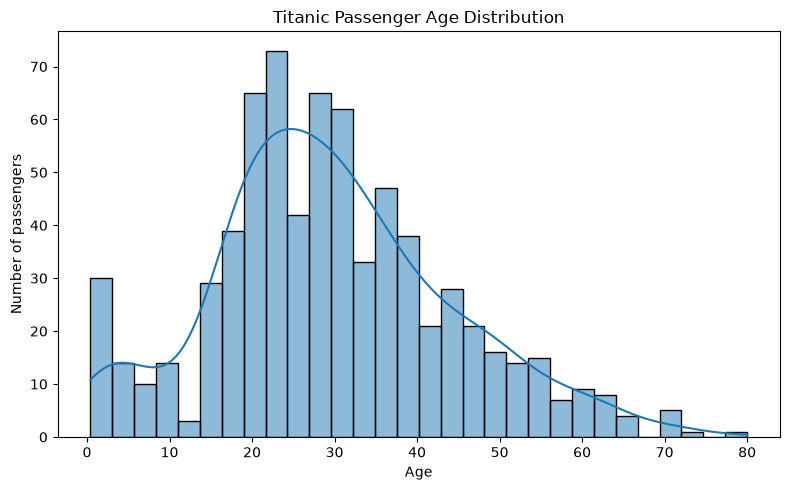

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(data=titanic, x="age", bins=30, kde=True)
plt.title("Titanic Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()

## 5. Export the cleaned dataset

The CSV is saved in the notebook's current working directory.

In [6]:
from pathlib import Path

output_path = Path("titanic_cleaned.csv")
cleaned.to_csv(output_path, index=False)
print(f"Cleaned dataset saved to: {output_path.resolve()}")
print(f"Exported dataset shape: {cleaned.shape}")

Cleaned dataset saved to: D:\BeeSkilled\week_1\week_1 Assignment\titanic_cleaned.csv
Exported dataset shape: (891, 19)
